## 02 EDA

- **Đầu vào:** `data/processed/games_cleaned.csv` (dữ liệu đã làm sạch ở notebook 01).
- **Mục 2.3:** khám phá tổng quan về giá, tương quan giữa các biến, lượt đề xuất, game miễn phí/trả phí và thể loại.
- **Mục 2.4:** phân tích trả lời trực tiếp từng câu hỏi nghiên cứu (RQ1, RQ2, RQ5).
- **Mục 2.5:** tổng kết câu trả lời và hạn chế.

### 2.1. Phân tích mối quan hệ giữa các biến

Phân tích mối quan hệ giữa các biến nhằm xác định những yếu tố có liên hệ với mức độ phổ biến và phản hồi của người chơi đối với các trò chơi trên Steam. Các biến được xem xét gồm giá bán (Price), số lượt đánh giá tích cực (Positive), số lượt đánh giá tiêu cực (Negative), lượng người chơi đồng thời cao nhất (Peak CCU), số lượt đề xuất (Recommendations), điểm Metacritic và thời gian chơi trung bình.

### 2.2. So sánh giữa các nhóm đối tượng

Các trò chơi được phân nhóm theo giá bán và thể loại. Việc so sánh giữa game miễn phí và game trả phí giúp khảo sát sự khác biệt về mức độ phổ biến và tỷ lệ đánh giá tích cực. Phân tích theo thể loại cho phép xác định những thể loại phổ biến và sự khác biệt về giá bán giữa chúng.

### 2.3. Khám phá dữ liệu tổng quan

#### 2.3.1. Khai báo thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
# Dùng dữ liệu đã làm sạch (tạo ở notebook 01_data_quality)
df = pd.read_csv("../data/processed/games_cleaned.csv", low_memory=False)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14

print("Kích thước dataset:", df.shape)
print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe(include="all").T)

print("\nSố lượng giá trị thiếu:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing"))

Kích thước dataset: (125846, 21)

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 125846 entries, 0 to 125845
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          125846 non-null  int64  
 1   Name                        125846 non-null  str    
 2   Release date                125846 non-null  str    
 3   Estimated owners            125846 non-null  str    
 4   Peak CCU                    125846 non-null  int64  
 5   Price                       125846 non-null  float64
 6   Discount                    125846 non-null  int64  
 7   DLC count                   125846 non-null  int64  
 8   Positive                    125846 non-null  int64  
 9   Negative                    125846 non-null  int64  
 10  User score                  40 non-null      float64
 11  Metacritic score            4258 non-null    float64
 12  Recommendations             12

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,125846.0,NaN,NaN,NaN,2032697.222621,1117368.087762,10.0,1083662.5,1949025.0,2938500.0,4437540.0
Name,125846,124642,Shadow of the Tomb Raider: Definitive Edition,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release date,125846,5140,2025-10-23,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated owners,125846,14,0 - 20000,75703,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Peak CCU,125846.0,NaN,NaN,NaN,53.191003,3681.214565,0.0,0.0,0.0,0.0,1013936.0
Price,125846.0,NaN,NaN,NaN,4.810724,12.489443,0.0,0.59,2.39,5.52,999.98
Discount,125846.0,NaN,NaN,NaN,17.882634,28.6219,0.0,0.0,0.0,36.0,100.0
DLC count,125846.0,NaN,NaN,NaN,0.535472,14.328929,0.0,0.0,0.0,0.0,3703.0
Positive,125846.0,NaN,NaN,NaN,1018.254907,27728.814551,0.0,0.0,4.0,35.0,7642084.0
Negative,125846.0,NaN,NaN,NaN,164.890422,5305.190176,0.0,0.0,1.0,10.0,1173003.0



Số lượng giá trị thiếu:


,Missing
User score,125806
Metacritic score,121588
Tags,42493
Categories,8966
Genres,8423
Peak CCU,0
Estimated owners,0
Release date,0
Name,0
id,0


#### 2.3.2. Phân phối giá game

Tổng số game có giá hợp lệ: 125846
Tổng các cột trong biểu đồ: 125846
Game miễn phí: 26658 (21.2%)
Game trả phí dưới 1 USD: 20261
Game từ 30 USD trở lên: 1146


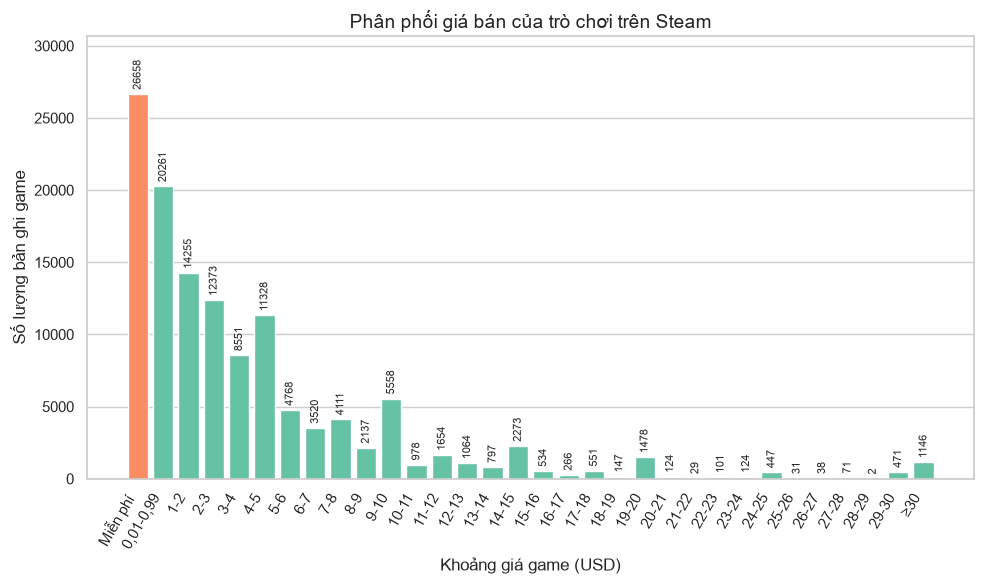

In [2]:
prices = df["Price"].dropna()
free = prices[prices == 0]
paid = prices[prices > 0]

edges = list(range(0, 31)) + [np.inf]
paid_labels = ["0,01-0,99"] + [f"{i}-{i+1}" for i in range(1, 30)] + ["≥30"]
paid_counts = (pd.cut(paid, bins=edges, labels=paid_labels, right=False)
                 .value_counts().reindex(paid_labels))

counts = pd.concat([pd.Series({"Miễn phí": len(free)}), paid_counts])
colors = [sns.color_palette()[1]] + [sns.color_palette()[0]] * len(paid_counts)

print("Tổng số game có giá hợp lệ:", len(prices))
print("Tổng các cột trong biểu đồ:", counts.sum())
print("Game miễn phí:", len(free), f"({len(free)/len(prices):.1%})")
print("Game trả phí dưới 1 USD:", paid_counts["0,01-0,99"])
print("Game từ 30 USD trở lên:", paid_counts["≥30"])

plt.figure()
ax = plt.gca()
ax.bar(range(len(counts)), counts.values, color=colors, edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%d", rotation=90, fontsize=8, padding=3)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=60, ha="right")
ax.grid(axis="x", visible=False)
ax.set(title="Phân phối giá bán của trò chơi trên Steam",
       xlabel="Khoảng giá game (USD)", ylabel="Số lượng bản ghi game")
plt.tight_layout()
plt.show()

Nhận xét:

1. Phân phối lệch phải rất mạnh, đa số game có giá thấp.

-Cột **miễn phí** cao nhất với 26.658 game (21,2%), tiếp theo là cột 0,01–0,99 USD với 20.261 game. Cộng lại có 46.919 game (khoảng 37,3% tổng số 125.846 game) có giá dưới 1 USD.

-Khoảng 74% game có giá dưới 5 USD và khoảng 90% dưới 10 USD.

-Số game giảm dần khi giá tăng. Nhóm từ 30 USD trở lên chỉ có 1.146 game, chiếm chưa tới 1%.

2. Phân khúc giá cao rất ít game.

-Từ 10 USD trở lên, mỗi khoảng chỉ còn vài trăm đến vài nghìn game, và từ 20 USD trở đi hầu hết các khoảng dưới 500 game (riêng 19–20 USD có 1.478 game).

Kết luận: thị trường Steam trong dữ liệu này tập trung vào game giá rẻ và game miễn phí, chủ yếu dưới 5 USD. Giá bán có xu hướng tập trung vào một số mức quen thuộc như 4,99, 9,99 và 14,99 USD thay vì trải đều.

#### 2.3.3. Ma trận tương quan giữa các biến số

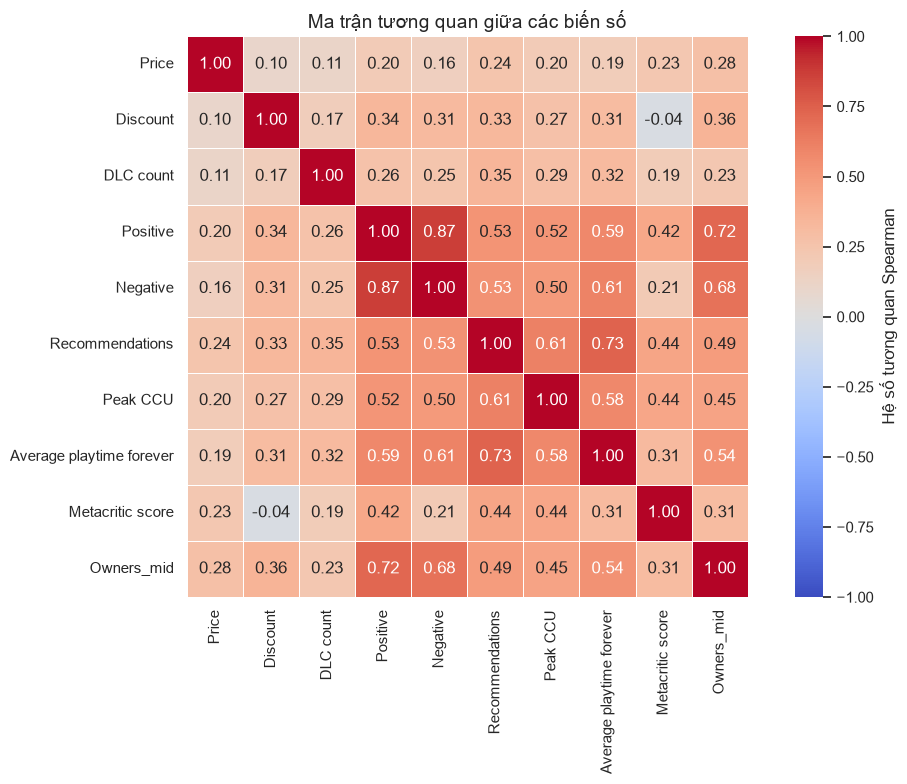

In [3]:
lo = df["Estimated owners"].str.split(" - ").str[0].astype(float)
hi = df["Estimated owners"].str.split(" - ").str[1].astype(float)
data = df.assign(Owners_mid=(lo + hi) / 2)   # đổi khoảng owners thành số (điểm giữa)

cols = ["Price", "Discount", "DLC count", "Positive", "Negative", "Recommendations",
        "Peak CCU", "Average playtime forever", "Metacritic score", "Owners_mid"]

corr = data[cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, square=True, cbar_kws={"label": "Hệ số tương quan Spearman"})
plt.title("Ma trận tương quan giữa các biến số")
plt.tight_layout()
plt.show()

-Nhận xét:

1.Tương quan mạnh (từ 0,5 trở lên):

-Positive ~ Negative: 0,87. Game có nhiều đánh giá tốt thường cũng có nhiều đánh giá xấu. Con số này phản ánh độ nổi tiếng

-Positive ~ Owners_mid: 0,72, và Negative ~ Owners_mid: 0,68. Càng nhiều người sở hữu thì càng nhiều đánh giá.

-Recommendations ~ Average playtime forever: 0,73, và Recommendations ~ Peak CCU: 0,61. Game được đề xuất nhiều thường được chơi lâu hơn và có nhiều người chơi đồng thời hơn.

2.Tương quan yếu (dưới 0,3):

-Price với hầu hết biến khác chỉ khoảng 0,1–0,28, nghĩa là giá không quyết định độ nổi tiếng.

#### 2.3.4. Mối quan hệ giữa lượt đề xuất và lượng người chơi

                so_game  ccu_trung_vi
nhom                                 
101-200            5881           0.0
201-500            5696           1.0
501-1.000          3066           2.0
1.001-5.000        4034           9.0
5.001-10.000        885          42.0
10.001-50.000      1060         179.5
50.001-100.000      199         756.0
>100.000            192        4004.0


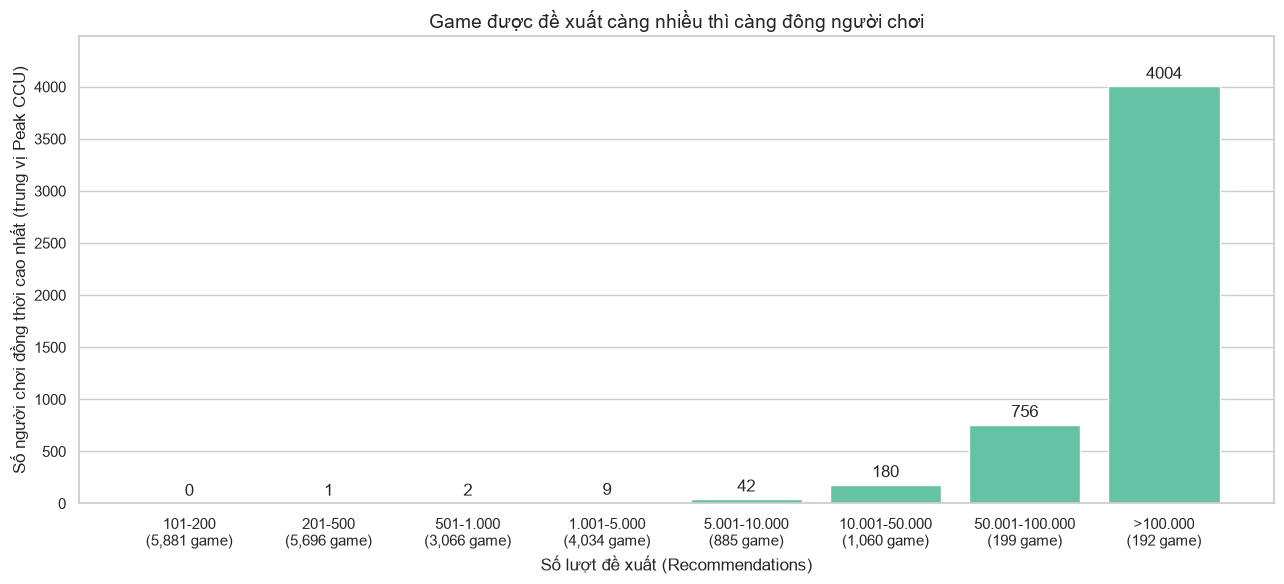

In [4]:
d = df[df["Recommendations"] > 0].copy()          # chỉ xét game có lượt đề xuất

edges  = [0, 200, 500, 1000, 5000, 10000, 50000, 100000, np.inf]
labels = ["101-200", "201-500", "501-1.000", "1.001-5.000",
          "5.001-10.000", "10.001-50.000", "50.001-100.000", ">100.000"]
d["nhom"] = pd.cut(d["Recommendations"], bins=edges, labels=labels, right=True)

tong_hop = d.groupby("nhom", observed=True).agg(
    so_game=("Peak CCU", "size"),
    ccu_trung_vi=("Peak CCU", "median"),
)
print(tong_hop)

plt.figure(figsize=(13, 6))
ax = plt.gca()
ax.bar(range(len(tong_hop)), tong_hop["ccu_trung_vi"], edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_xticks(range(len(tong_hop)))
ax.set_xticklabels([f"{l}\n({n:,} game)" for l, n in zip(tong_hop.index, tong_hop["so_game"])])
ax.grid(axis="x", visible=False)
ax.set_ylim(0, tong_hop["ccu_trung_vi"].max() * 1.12)
ax.set(title="Game được đề xuất càng nhiều thì càng đông người chơi",
       xlabel="Số lượt đề xuất (Recommendations)",
       ylabel="Số người chơi đồng thời cao nhất (trung vị Peak CCU)")
plt.tight_layout()
plt.show()

Nhận xét

-Lượt đề xuất càng nhiều thì người chơi càng đông, và tăng rất nhanh ở nhóm cuối. Trung vị Peak CCU là 0–2 ở nhóm dưới 1.000 lượt, 9 ở nhóm 1.001–5.000, rồi 180 ở nhóm 10.001–50.000, 756 ở nhóm 50.001–100.000 và 4.004 ở nhóm trên 100.000.

-Phần lớn game nằm ở các nhóm thấp. Hai nhóm dưới 500 lượt có tới 11.577 game (khoảng 55%), trong khi nhóm trên 100.000 lượt chỉ có 192 game. Cột cao nhưng chỉ đại diện cho một nhóm nhỏ game rất nổi tiếng.

-Các cột đầu gần như bằng 0 nhưng không phải lỗi. Game có ít lượt đề xuất thường chỉ có 0–2 người chơi đồng thời ở thời điểm ghi nhận, nên cột rất thấp, chỉ thấy số ghi trên đầu cột.

#### 2.3.5.  So sánh game miễn phí và game trả phí

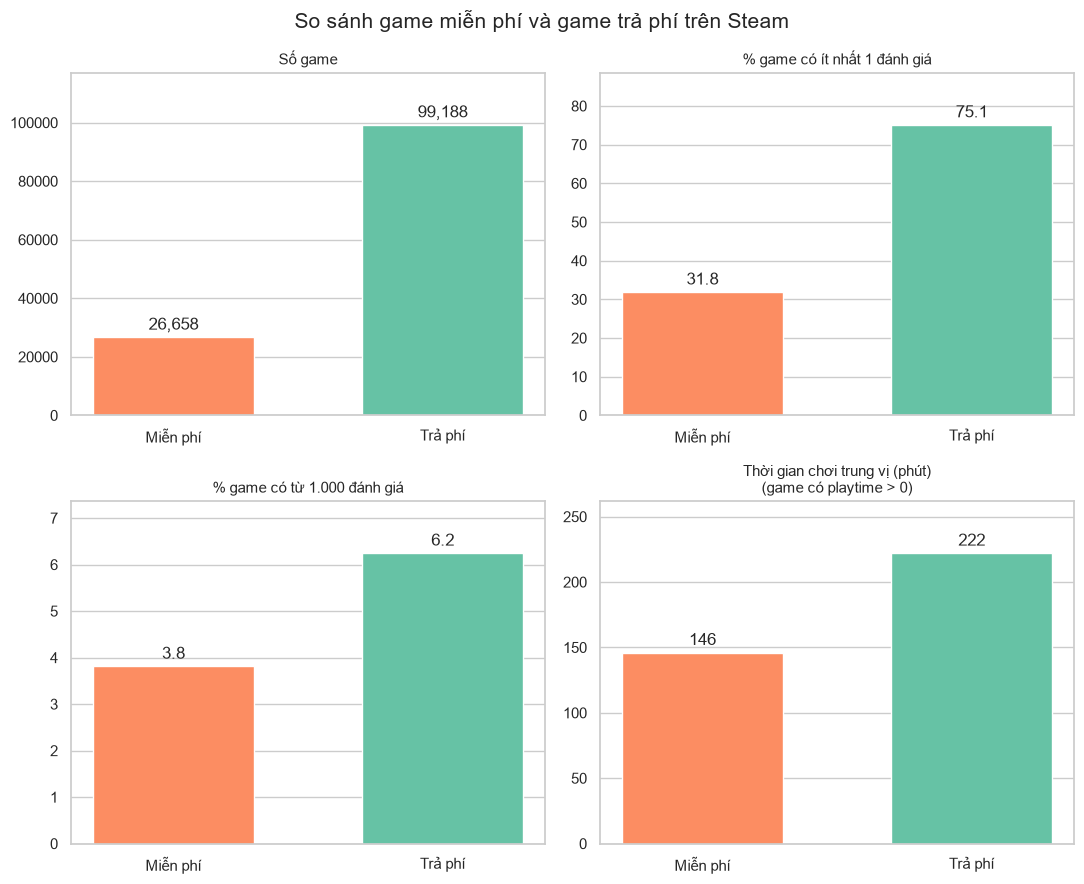

In [5]:
data = df.dropna(subset=["Price"]).copy()
data["Nhóm"] = np.where(data["Price"] == 0, "Miễn phí", "Trả phí")
data["Reviews"] = data["Positive"] + data["Negative"]

order = ["Miễn phí", "Trả phí"]
g = data.groupby("Nhóm")

metrics = [   # (tiêu đề, số liệu theo nhóm, định dạng số)
    ("Số game", g.size(), "{:,.0f}"),
    ("% game có ít nhất 1 đánh giá", g["Reviews"].apply(lambda s: (s > 0).mean() * 100), "{:.1f}"),
    ("% game có từ 1.000 đánh giá", g["Reviews"].apply(lambda s: (s >= 1000).mean() * 100), "{:.1f}"),
    ("Thời gian chơi trung vị (phút)\n(game có playtime > 0)",
     data[data["Average playtime forever"] > 0].groupby("Nhóm")["Average playtime forever"].median(), "{:,.0f}"),
]

colors = [sns.color_palette()[1], sns.color_palette()[0]]   # cam = miễn phí, xanh = trả phí
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (title, values, fmt) in zip(axes.ravel(), metrics):
    values = values.loc[order]
    ax.bar(order, values.values, color=colors, edgecolor="white", width=0.6)
    ax.bar_label(ax.containers[0], labels=[fmt.format(v) for v in values.values], padding=3)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("So sánh game miễn phí và game trả phí trên Steam", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

1. Số lượng: game trả phí có 99.188 game (78,8%), game miễn phí có 26.658 game (21,2%). Game trả phí nhiều gấp khoảng 3,7 lần.

2. Game miễn phí thường chưa có ai đánh giá. Chỉ 31,8% game miễn phí có ít nhất 1 đánh giá, trong khi game trả phí là 75,1%.

3. Game trả phí có tỷ lệ game nổi tiếng cao hơn: 6,2% game trả phí có từ 1.000 đánh giá, so với 3,8% ở game miễn phí. Tỷ lệ này tính trên tất cả game, nên bị kéo xuống ở game miễn phí vì 68,2% game miễn phí không có đánh giá nào.

4. Game trả phí được chơi lâu hơn: thời gian chơi trung vị (chỉ tính game có thời gian chơi > 0) là 222 phút, so với 146 phút ở game miễn phí.

Kết luận: game miễn phí vừa ít hơn, vừa có nhiều game chưa có người dùng. Game trả phí có tỷ lệ game nổi tiếng cao hơn và được chơi lâu hơn. Tuy nhiên, nếu chỉ xét game đã có ít nhất 1 đánh giá thì game miễn phí lại có tỷ lệ đạt từ 1.000 đánh giá cao hơn (12,0% so với 8,3%). Mức độ đánh giá tích cực theo nhóm giá được so sánh ở mục 2.4.7.

#### 2.3.6. So sánh giá giữa các thể loại game

                       so_game  pct_free  gia_tv
Genre                                           
Casual                   51670     14.72    2.99
Indie                    82883     14.41    2.99
Racing                    4169     13.53    3.49
Action                   47343     15.54    3.74
Adventure                46291     13.76    3.99
Strategy                 23057     15.10    3.99
Sports                    4970     13.80    3.99
Simulation               24909     13.17    3.99
Massively Multiplayer     2595     55.61    4.99
RPG                      21576     15.64    4.99
Utilities                 1091     29.15    4.99
Design & Illustration      584     24.66    7.99


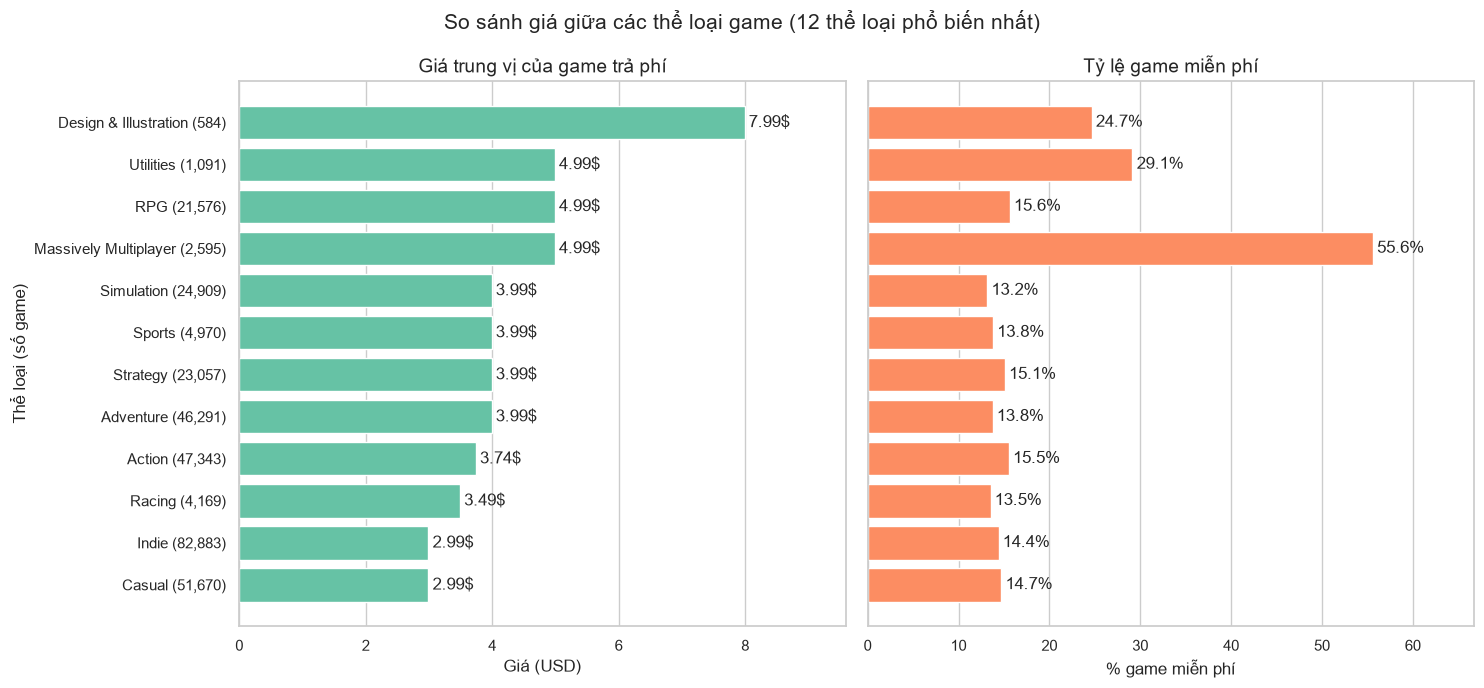

In [6]:
d = df.dropna(subset=["Genres", "Price"]).copy()
d["Genre"] = d["Genres"].str.split(",")
d = d.explode("Genre")                     # 1 game nhiều thể loại -> mỗi thể loại 1 dòng
d["Genre"] = d["Genre"].str.strip()

# bỏ 2 nhãn không phải thể loại nội dung: Free To Play (trùng với giá) và Early Access (trạng thái phát hành)
d = d[~d["Genre"].isin(["Free To Play", "Early Access"])]

top = d["Genre"].value_counts().head(12).index
d = d[d["Genre"].isin(top)]

tong_hop = d.groupby("Genre").agg(
    so_game=("Price", "size"),
    pct_free=("Price", lambda s: (s == 0).mean() * 100),
    gia_tv=("Price", lambda s: s[s > 0].median()),
).sort_values("gia_tv")
print(tong_hop.round(2))

labels = [f"{g} ({n:,})" for g, n in zip(tong_hop.index, tong_hop["so_game"])]
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

axes[0].barh(labels, tong_hop["gia_tv"], color=sns.color_palette()[0], edgecolor="white")
axes[0].bar_label(axes[0].containers[0], labels=[f"{v:.2f}$" for v in tong_hop["gia_tv"]], padding=3)
axes[0].set_xlim(0, tong_hop["gia_tv"].max() * 1.2)
axes[0].set(title="Giá trung vị của game trả phí", xlabel="Giá (USD)", ylabel="Thể loại (số game)")

axes[1].barh(labels, tong_hop["pct_free"], color=sns.color_palette()[1], edgecolor="white")
axes[1].bar_label(axes[1].containers[0], labels=[f"{v:.1f}%" for v in tong_hop["pct_free"]], padding=3)
axes[1].set_xlim(0, tong_hop["pct_free"].max() * 1.2)
axes[1].set(title="Tỷ lệ game miễn phí", xlabel="% game miễn phí")

for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("So sánh giá giữa các thể loại game (12 thể loại phổ biến nhất)", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét

1. Giá trung vị giữa các thể loại chênh nhau không nhiều.

-Hầu hết thể loại nằm trong khoảng 2,99–4,99 USD.

-Casual và Indie rẻ nhất (2,99 USD). Hai thể loại này cũng có nhiều game nhất (51.670 và 82.883 game), nên phần lớn thị trường là game giá rẻ.

-RPG, Utilities và Massively Multiplayer cùng ở mức 4,99 USD, đắt hơn nhóm rẻ nhất khoảng 1,7 lần.

### 2.4. Phân tích theo câu hỏi nghiên cứu

Phần này trả lời trực tiếp 3 câu hỏi nghiên cứu đã chốt:

- **RQ1.** Những yếu tố nào có mối liên hệ với mức độ phổ biến của một trò chơi trên Steam?
- **RQ2.** Những yếu tố nào có mối liên hệ với mức độ đánh giá tích cực của người chơi trên Steam?
- **RQ5.** Giá bán có mối liên hệ như thế nào với mức độ phổ biến và mức độ đánh giá của trò chơi trên Steam?

Các chỉ số dùng chung:

- **Owners_mid**: điểm giữa của khoảng `Estimated owners` (ví dụ "20000 - 50000" → 35.000).
- **Total reviews** = Positive + Negative.
- **Positive ratio** = Positive / Total reviews × 100 (%). Chỉ tính cho game có **từ 10 đánh giá trở lên**, vì game quá ít đánh giá thì tỷ lệ không đáng tin (ví dụ 1/1 = 100%).
- **Nhóm giá**: Miễn phí (0 USD), Thấp (dưới 5 USD), Trung bình (5 đến dưới 15 USD), Cao (từ 15 USD). Mốc 5 và 15 USD được chọn vì khoảng 74% game có giá dưới 5 USD (mục 2.3.2).

In [7]:
# Chuẩn bị các cột dùng chung cho phần phân tích theo câu hỏi nghiên cứu
rq = df.copy()

# Estimated owners là một khoảng (ví dụ "20000 - 50000") nên lấy điểm giữa để có 1 con số
owners_min = rq["Estimated owners"].str.split(" - ").str[0].astype(float)
owners_max = rq["Estimated owners"].str.split(" - ").str[1].astype(float)
rq["Owners_mid"] = (owners_min + owners_max) / 2

# Tổng số đánh giá và tỷ lệ đánh giá tích cực (%)
rq["Total reviews"] = rq["Positive"] + rq["Negative"]
rq["Positive ratio"] = rq["Positive"] / rq["Total reviews"] * 100   # game chưa có đánh giá -> NaN

# Chia nhóm giá
def nhom_gia(gia):
    if gia == 0:
        return "Miễn phí"
    elif gia < 5:
        return "Thấp (<5 USD)"
    elif gia < 15:
        return "Trung bình (5-15 USD)"
    else:
        return "Cao (≥15 USD)"

rq["Nhóm giá"] = rq["Price"].apply(nhom_gia)
thu_tu_gia = ["Miễn phí", "Thấp (<5 USD)", "Trung bình (5-15 USD)", "Cao (≥15 USD)"]

# Chỉ dùng game có từ 10 đánh giá khi tính tỷ lệ tích cực
rq_review = rq[rq["Total reviews"] >= 10]

# Bảng theo thể loại: 1 game có nhiều thể loại -> mỗi thể loại 1 dòng
the_loai = rq.dropna(subset=["Genres"]).copy()
the_loai["Genre"] = the_loai["Genres"].str.split(",")
the_loai = the_loai.explode("Genre")
the_loai["Genre"] = the_loai["Genre"].str.strip()
# bỏ 2 nhãn không phải thể loại nội dung (giống mục 2.3.6)
the_loai = the_loai[~the_loai["Genre"].isin(["Free To Play", "Early Access"])]
top_the_loai = the_loai["Genre"].value_counts().head(12).index
the_loai = the_loai[the_loai["Genre"].isin(top_the_loai)]

print("Tổng số game:", len(rq))
print("Số game thiếu giá:", rq["Price"].isna().sum())
print("Số game có từ 10 đánh giá:", len(rq_review))
print("Số game theo nhóm giá:")
display(rq["Nhóm giá"].value_counts().reindex(thu_tu_gia).to_frame("Số game"))

Tổng số game: 125846
Số game thiếu giá: 0
Số game có từ 10 đánh giá: 56662
Số game theo nhóm giá:


,Số game
Nhóm giá,
Miễn phí,26658
Thấp (<5 USD),66768
Trung bình (5-15 USD),26860
Cao (≥15 USD),5560


#### 2.4.1. RQ1 – Số người sở hữu và lượng người chơi đồng thời

Câu hỏi phụ: *Lượng người sở hữu ước tính có tương quan mạnh với đỉnh điểm người chơi đồng thời (Peak CCU) không?*

Dùng tương quan **Spearman** vì dữ liệu lệch rất mạnh (đa số game có Peak CCU = 0) và Estimated owners chỉ là khoảng.

Tương quan Spearman (tất cả game):


,Owners_mid,Peak CCU,Total reviews,Recommendations
Owners_mid,1.00,0.45,0.73,0.49
Peak CCU,0.45,1.00,0.51,0.61
Total reviews,0.73,0.51,1.00,0.53
Recommendations,0.49,0.61,0.53,1.00


Tương quan Spearman (chỉ game có Peak CCU > 0):


,Owners_mid,Peak CCU,Total reviews,Recommendations
Owners_mid,1.00,0.54,0.86,0.68
Peak CCU,0.54,1.00,0.61,0.61
Total reviews,0.86,0.61,1.00,0.82
Recommendations,0.68,0.61,0.82,1.00


,so_game,pct_co_nguoi_choi,ccu_trung_vi,owners_mid
Estimated owners,,,,
0 - 0,24572,0.0,0.0,0.0
0 - 20000,75703,10.3,0.0,10000.0
20000 - 50000,11397,25.0,0.0,35000.0
50000 - 100000,5355,42.1,0.0,75000.0
100000 - 200000,3454,62.5,1.0,150000.0
200000 - 500000,2856,79.1,6.0,350000.0
500000 - 1000000,1155,92.2,36.0,750000.0
1000000 - 2000000,729,95.9,125.0,1500000.0
2000000 - 5000000,405,97.5,424.0,3500000.0


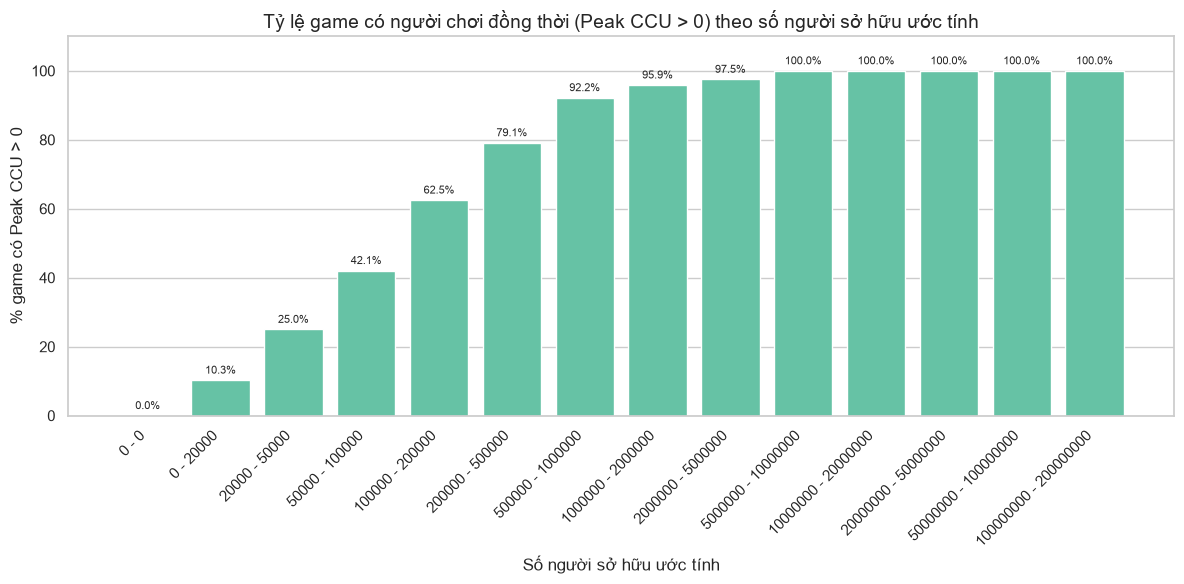

In [8]:
cot = ["Owners_mid", "Peak CCU", "Total reviews", "Recommendations"]

print("Tương quan Spearman (tất cả game):")
display(rq[cot].corr(method="spearman").round(2))

print("Tương quan Spearman (chỉ game có Peak CCU > 0):")
display(rq[rq["Peak CCU"] > 0][cot].corr(method="spearman").round(2))

# Xem theo từng khoảng số người sở hữu
bang_owners = rq.groupby("Estimated owners").agg(
    so_game=("Peak CCU", "size"),
    pct_co_nguoi_choi=("Peak CCU", lambda s: (s > 0).mean() * 100),
    ccu_trung_vi=("Peak CCU", "median"),
    owners_mid=("Owners_mid", "first"),
).sort_values("owners_mid")
display(bang_owners.round(1))

plt.figure(figsize=(12, 6))
ax = plt.gca()
ax.bar(range(len(bang_owners)), bang_owners["pct_co_nguoi_choi"], edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xticks(range(len(bang_owners)))
ax.set_xticklabels(bang_owners.index, rotation=45, ha="right")
ax.set_ylim(0, 110)
ax.grid(axis="x", visible=False)
ax.set(title="Tỷ lệ game có người chơi đồng thời (Peak CCU > 0) theo số người sở hữu ước tính",
       xlabel="Số người sở hữu ước tính", ylabel="% game có Peak CCU > 0")
plt.tight_layout()
plt.show()

Nhận xét:

- Tương quan Spearman giữa Owners_mid và Peak CCU là **0,45** trên toàn bộ game và **0,54** khi chỉ xét game có Peak CCU > 0. Đây là mức **trung bình**, chưa phải tương quan mạnh.
- Tuy vậy xu hướng theo nhóm rất rõ: tỷ lệ game có người chơi đồng thời tăng từ 10,3% (nhóm 0–20.000 người sở hữu) lên 62,5% (100.000–200.000), 92,2% (500.000–1.000.000) và 100% từ 5 triệu người sở hữu trở lên. Peak CCU trung vị cũng tăng từ 0 lên 36, rồi 2.146 ở nhóm 5–10 triệu.
- Tương quan chưa mạnh vì: 84% game có Peak CCU = 0; Estimated owners chỉ là khoảng rộng; Peak CCU là đỉnh tại một thời điểm, còn số người sở hữu là tích lũy cả đời game.
- Biến liên quan nhiều nhất với số người sở hữu là **tổng số đánh giá** (0,73), sau đó đến lượt đề xuất (0,49).

**Trả lời câu hỏi phụ:** số người sở hữu và Peak CCU có liên hệ cùng chiều rõ ràng nhưng ở mức trung bình (Spearman 0,45), không phải tương quan mạnh.

#### 2.4.2. RQ1 – Mức độ phổ biến theo thể loại

Vì Peak CCU trung vị của hầu hết thể loại đều bằng 0, ta so sánh **tỷ lệ game phổ biến** trong mỗi thể loại:

- % game có Peak CCU > 0
- % game có từ 20.000 người sở hữu trở lên

,so_game,pct_co_nguoi_choi,pct_tu_20k
Genre,,,
Design & Illustration,584,31.3,14.2
Utilities,1091,28.7,14.8
Massively Multiplayer,2595,24.8,32.4
RPG,21576,22.9,27.9
Strategy,23057,21.9,25.7
Simulation,24909,21.6,20.7
Sports,4970,17.4,18.7
Adventure,46291,17.0,23.8
Action,47343,15.2,23.7


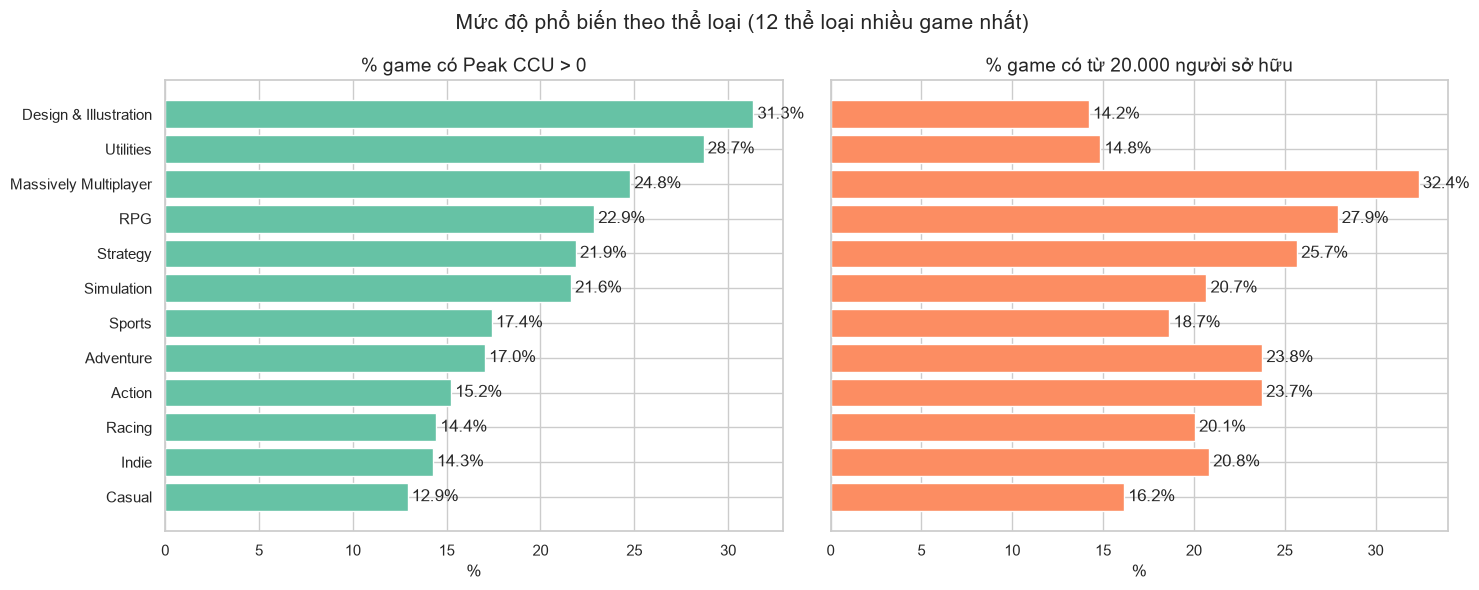

In [9]:
pho_bien = the_loai.groupby("Genre").agg(
    so_game=("Peak CCU", "size"),
    pct_co_nguoi_choi=("Peak CCU", lambda s: (s > 0).mean() * 100),
    pct_tu_20k=("Owners_mid", lambda s: (s >= 35000).mean() * 100),   # 35.000 = điểm giữa khoảng "20000 - 50000"
).sort_values("pct_co_nguoi_choi")
display(pho_bien.sort_values("pct_co_nguoi_choi", ascending=False).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].barh(pho_bien.index, pho_bien["pct_co_nguoi_choi"])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].set(title="% game có Peak CCU > 0", xlabel="%")

axes[1].barh(pho_bien.index, pho_bien["pct_tu_20k"], color=sns.color_palette()[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set(title="% game có từ 20.000 người sở hữu", xlabel="%")

fig.suptitle("Mức độ phổ biến theo thể loại (12 thể loại nhiều game nhất)", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét:

- **Massively Multiplayer, RPG, Strategy, Simulation** có tỷ lệ game phổ biến cao nhất: 21,6–24,8% game có người chơi đồng thời. Massively Multiplayer có tỷ lệ game từ 20.000 người sở hữu cao nhất (32,4%), sau đó là RPG (27,9%) và Strategy (25,7%).
- **Casual, Indie, Racing** có tỷ lệ thấp nhất (12,9–14,4% game có người chơi đồng thời). Casual và Indie lại là hai thể loại có nhiều game nhất (51.670 và 82.883 game), nên cạnh tranh rất đông và phần lớn game ít người chơi.
- Design & Illustration và Utilities có tỷ lệ cao (31,3% và 28,7%) nhưng đây là phần mềm chứ không phải game, và số lượng ít (584 và 1.091), nên không dùng để kết luận về game.

**Trả lời RQ1 (thể loại):** thể loại có liên hệ với mức độ phổ biến. Game nhiều người chơi, nhập vai và chiến thuật có tỷ lệ phổ biến cao hơn, còn Casual và Indie có tỷ lệ thấp nhất.

#### 2.4.3. RQ2 – Phân phối tỷ lệ đánh giá tích cực

Cột `User score` không dùng được vì gần như toàn bộ chưa có điểm (xem kết quả bên dưới). Vì vậy ta dùng **Positive ratio** làm thước đo đánh giá của người chơi.

Số game có User score: 40 / 125846
Số game có từ 10 đánh giá: 56662
Tỷ lệ tích cực trung bình: 77.2 %
Tỷ lệ tích cực trung vị: 81.2 %

Các phân vị:


,Positive ratio (%)
0.10,51.9
0.25,67.3
0.50,81.2
0.75,91.0
0.90,96.4


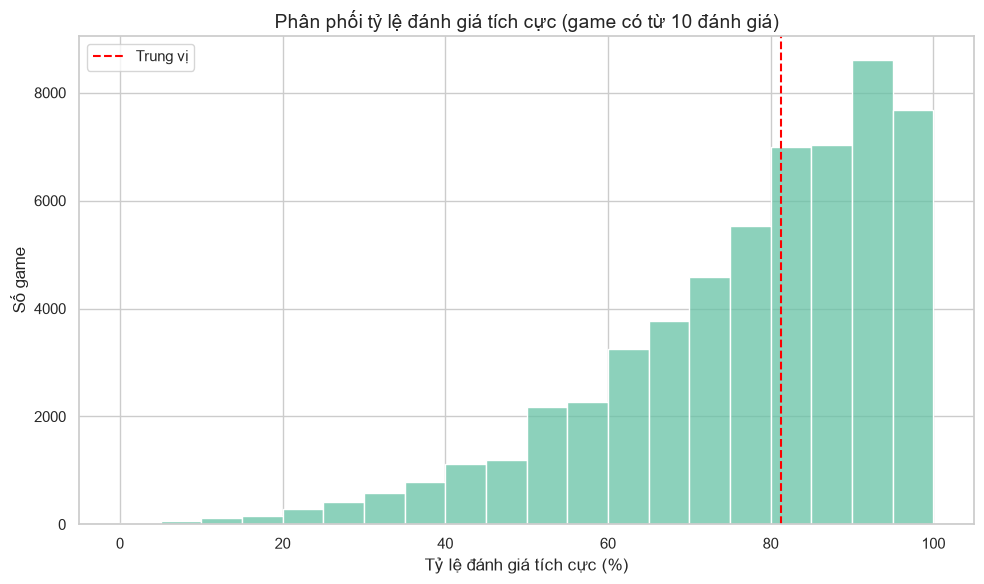

In [10]:
print("Số game có User score:", rq["User score"].notna().sum(), "/", len(rq))
print("Số game có từ 10 đánh giá:", len(rq_review))
print("Tỷ lệ tích cực trung bình:", round(rq_review["Positive ratio"].mean(), 1), "%")
print("Tỷ lệ tích cực trung vị:", round(rq_review["Positive ratio"].median(), 1), "%")

print("\nCác phân vị:")
display(rq_review["Positive ratio"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_frame("Positive ratio (%)"))

plt.figure()
sns.histplot(rq_review["Positive ratio"], bins=20)
plt.axvline(rq_review["Positive ratio"].median(), color="red", linestyle="--", label="Trung vị")
plt.legend()
plt.title("Phân phối tỷ lệ đánh giá tích cực (game có từ 10 đánh giá)")
plt.xlabel("Tỷ lệ đánh giá tích cực (%)")
plt.ylabel("Số game")
plt.tight_layout()
plt.show()

Nhận xét:

- Chỉ 40 game có `User score` (các game còn lại chưa có điểm), nên cột này gần như rỗng.
- Có 56.662 game có từ 10 đánh giá. Tỷ lệ tích cực trung bình là 77,2%, trung vị 81,2%.
- Phân phối lệch trái: một nửa số game có trên 81% đánh giá tích cực, chỉ 10% game có dưới 51,9%. Nghĩa là phần lớn game trên Steam được người chơi đánh giá tốt, nên khi so sánh giữa các nhóm cần chú ý những chênh lệch vài điểm phần trăm.

#### 2.4.4. RQ2 – Đánh giá của người chơi so với điểm Metacritic

Câu hỏi phụ: *Điểm đánh giá của người dùng có tương đồng với điểm đánh giá từ giới phê bình chuyên nghiệp không?*

Game chưa có điểm Metacritic đã được để trống ở bước làm sạch (notebook 01), nên chỉ xét game có điểm Metacritic.

Số game có cả điểm Metacritic và từ 10 đánh giá: 4145
Điểm Metacritic trung bình: 73.8
Tỷ lệ tích cực trung bình của nhóm này: 80.6 %
Tương quan Spearman: 0.58


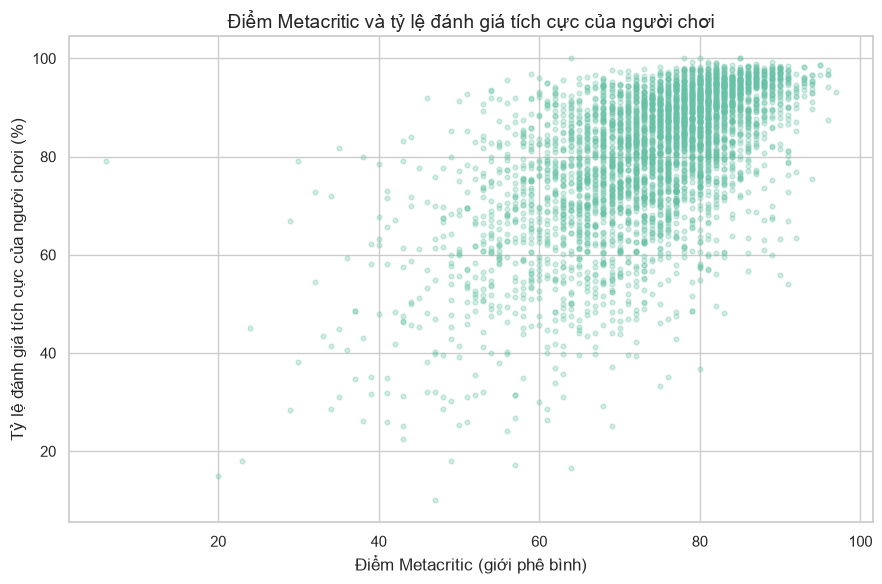

In [11]:
meta = rq_review[rq_review["Metacritic score"].notna()]

print("Số game có cả điểm Metacritic và từ 10 đánh giá:", len(meta))
print("Điểm Metacritic trung bình:", round(meta["Metacritic score"].mean(), 1))
print("Tỷ lệ tích cực trung bình của nhóm này:", round(meta["Positive ratio"].mean(), 1), "%")
print("Tương quan Spearman:", round(meta["Metacritic score"].corr(meta["Positive ratio"], method="spearman"), 2))

plt.figure(figsize=(9, 6))
plt.scatter(meta["Metacritic score"], meta["Positive ratio"], alpha=0.3, s=12)
plt.title("Điểm Metacritic và tỷ lệ đánh giá tích cực của người chơi")
plt.xlabel("Điểm Metacritic (giới phê bình)")
plt.ylabel("Tỷ lệ đánh giá tích cực của người chơi (%)")
plt.tight_layout()
plt.show()

Nhận xét:

- Chỉ có 4.145 game vừa có điểm Metacritic vừa có từ 10 đánh giá. Đây thường là game lớn, được giới phê bình chú ý, nên không đại diện cho toàn bộ Steam.
- Tương quan Spearman là **0,58**: game được giới phê bình chấm cao thường cũng được người chơi đánh giá tốt, nhưng hai bên không hoàn toàn trùng nhau. Trên biểu đồ có nhiều game điểm Metacritic khá nhưng tỷ lệ tích cực thấp, và ngược lại.
- Điểm Metacritic (thang 100) và tỷ lệ tích cực (%) là hai thang đo khác nhau, nên chỉ so sánh **xu hướng**, không so sánh trực tiếp con số (73,8 điểm và 80,6%).

**Trả lời câu hỏi phụ:** đánh giá của người chơi và giới phê bình tương đồng ở mức khá (Spearman 0,58), cùng chiều nhưng không trùng khớp.

#### 2.4.5. RQ2 – Tỷ lệ đánh giá tích cực theo thể loại

,so_game,ty_le_tich_cuc_trung_vi
Genre,,
Casual,21804,82.4
Indie,40583,81.8
Adventure,23961,81.2
Action,23898,80.0
RPG,10951,80.0
Strategy,11613,79.0
Racing,2054,78.1
Sports,2540,77.6
Design & Illustration,336,77.5


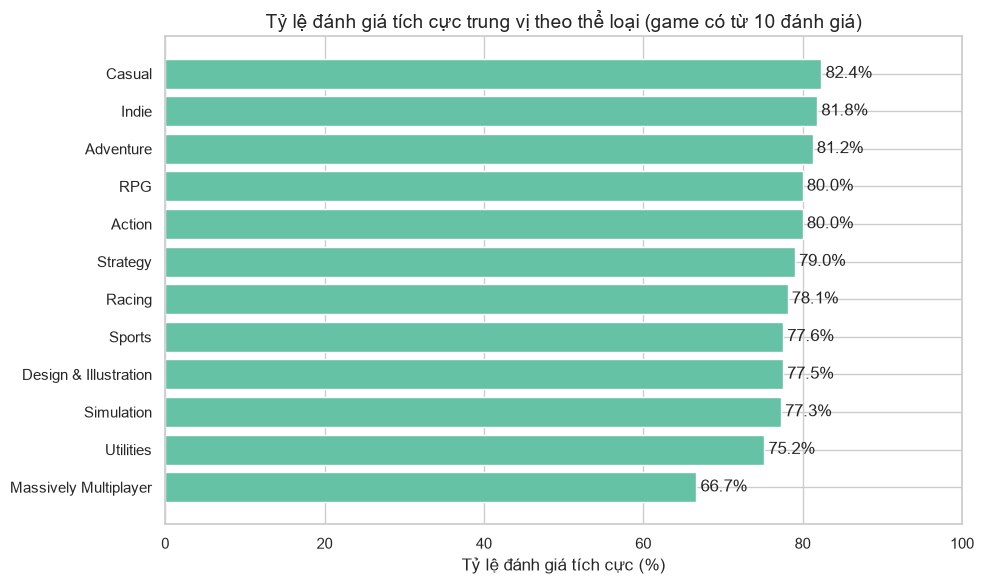

In [12]:
danh_gia_tl = the_loai[the_loai["Total reviews"] >= 10].groupby("Genre")["Positive ratio"].agg(["size", "median"])
danh_gia_tl.columns = ["so_game", "ty_le_tich_cuc_trung_vi"]
danh_gia_tl = danh_gia_tl.sort_values("ty_le_tich_cuc_trung_vi")
display(danh_gia_tl.sort_values("ty_le_tich_cuc_trung_vi", ascending=False).round(1))

plt.figure(figsize=(10, 6))
ax = plt.gca()
ax.barh(danh_gia_tl.index, danh_gia_tl["ty_le_tich_cuc_trung_vi"])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 100)
ax.set(title="Tỷ lệ đánh giá tích cực trung vị theo thể loại (game có từ 10 đánh giá)",
       xlabel="Tỷ lệ đánh giá tích cực (%)")
plt.tight_layout()
plt.show()

Nhận xét:

- Hầu hết thể loại có tỷ lệ tích cực trung vị gần nhau, từ 75% đến 82%. Casual (82,4%), Indie (81,8%) và Adventure (81,2%) cao nhất.
- **Massively Multiplayer thấp hơn hẳn** (66,7%), thấp hơn các thể loại còn lại từ 8,5 (Utilities) đến 15,7 điểm phần trăm (Casual).
- Điều đáng chú ý: Massively Multiplayer thuộc nhóm phổ biến nhất ở RQ1 nhưng lại có đánh giá thấp nhất. Ngược lại, Casual và Indie ít phổ biến nhưng được đánh giá tốt. Như vậy **phổ biến không đồng nghĩa với được đánh giá cao**.

#### 2.4.6. RQ2 – Tỷ lệ đánh giá tích cực theo tính năng

So sánh tỷ lệ tích cực trung vị giữa game **có** và **không có** một số tính năng: có Achievements (thành tựu) và một số nhãn trong cột `Categories`.

,Tính năng,Số game có,Trung vị khi có (%),Trung vị khi không có (%),Chênh lệch
3,Online PvP,5106,76.5,81.8,-5.3
2,Multi-player,11800,78.6,82.0,-3.4
4,Co-op,6591,79.7,81.6,-1.9
6,Full controller support,15528,85.5,79.4,6.1
5,Steam Cloud,19486,85.3,78.6,6.7
0,Có Achievements,36606,83.3,76.5,6.8
1,Single-player,53702,81.8,73.5,8.2


Tương quan Spearman giữa số Achievements và tỷ lệ tích cực: 0.16


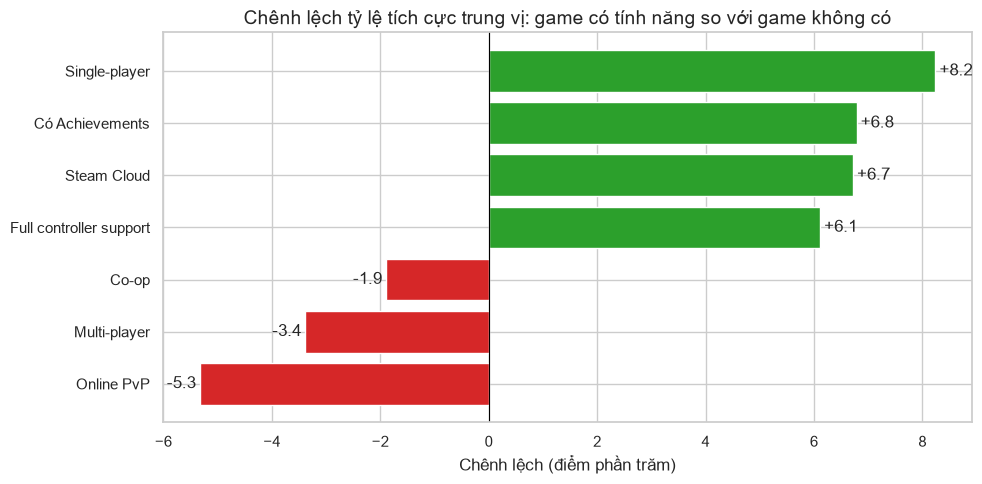

In [13]:
ket_qua = []

# Achievements: game có ít nhất 1 thành tựu hay không
co = rq_review["Achievements"] > 0
ket_qua.append(["Có Achievements", co.sum(),
                rq_review.loc[co, "Positive ratio"].median(),
                rq_review.loc[~co, "Positive ratio"].median()])

# Một số tính năng trong cột Categories
danh_sach = rq_review["Categories"].fillna("").str.split(",")
danh_sach = danh_sach.apply(lambda ds: [x.strip() for x in ds])

tinh_nang = ["Single-player", "Multi-player", "Online PvP", "Co-op", "Steam Cloud", "Full controller support"]
for tn in tinh_nang:
    co = danh_sach.apply(lambda ds: tn in ds)
    ket_qua.append([tn, co.sum(),
                    rq_review.loc[co, "Positive ratio"].median(),
                    rq_review.loc[~co, "Positive ratio"].median()])

bang_tn = pd.DataFrame(ket_qua, columns=["Tính năng", "Số game có", "Trung vị khi có (%)", "Trung vị khi không có (%)"])
bang_tn["Chênh lệch"] = bang_tn["Trung vị khi có (%)"] - bang_tn["Trung vị khi không có (%)"]
bang_tn = bang_tn.sort_values("Chênh lệch")
display(bang_tn.round(1))

print("Tương quan Spearman giữa số Achievements và tỷ lệ tích cực:",
      round(rq_review["Achievements"].corr(rq_review["Positive ratio"], method="spearman"), 2))

mau = ["tab:red" if x < 0 else "tab:green" for x in bang_tn["Chênh lệch"]]
plt.figure(figsize=(10, 5))
ax = plt.gca()
ax.barh(bang_tn["Tính năng"], bang_tn["Chênh lệch"], color=mau)
ax.bar_label(ax.containers[0], fmt="%+.1f", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Chênh lệch tỷ lệ tích cực trung vị: game có tính năng so với game không có",
       xlabel="Chênh lệch (điểm phần trăm)")
plt.tight_layout()
plt.show()

Nhận xét:

- Game **có Achievements** có tỷ lệ tích cực trung vị 83,3%, cao hơn game không có (76,5%) khoảng 6,8 điểm. Tuy nhiên tương quan giữa *số lượng* Achievements và tỷ lệ tích cực chỉ là 0,16 (yếu): có thành tựu thì liên quan đến đánh giá tốt hơn, nhưng nhiều thành tựu hơn thì không tốt hơn bao nhiêu.
- **Steam Cloud** (+6,7) và **Full controller support** (+6,1) cũng đi kèm đánh giá cao hơn. Đây là những tính năng cho thấy nhà phát triển đầu tư hoàn thiện game.
- Single-player có chênh lệch lớn nhất (+8,2), nhưng chỉ có 2.960 game không có nhãn này, nên nhóm so sánh khá nhỏ.
- **Multi-player** (−3,4) và **Online PvP** (−5,3) đi kèm đánh giá thấp hơn, phù hợp với kết quả Massively Multiplayer ở mục 2.4.5.

**Trả lời RQ2:** đánh giá tích cực có liên hệ với thể loại (Massively Multiplayer thấp hơn hẳn) và với các tính năng hoàn thiện game (Achievements, Steam Cloud, hỗ trợ tay cầm). Game chơi trực tuyến nhiều người có đánh giá thấp hơn. Mức chênh lệch chỉ khoảng 3–8 điểm phần trăm, và đây là **mối liên hệ**, không chứng minh tính năng *gây ra* đánh giá tốt.

#### 2.4.7. RQ5 – Nhóm giá với mức độ phổ biến và đánh giá

,so_game,pct_co_nguoi_choi,ccu_trung_binh,pct_tu_20k,ty_le_tich_cuc_trung_vi
Nhóm giá,,,,,
Miễn phí,26658,8.2,124.4,14.6,78.3
Thấp (<5 USD),66768,13.4,11.6,21.5,81.0
Trung bình (5-15 USD),26860,24.9,42.5,22.2,83.6
Cao (≥15 USD),5560,33.3,262.5,24.5,80.3


Tương quan Spearman giữa giá và tỷ lệ tích cực: 0.12


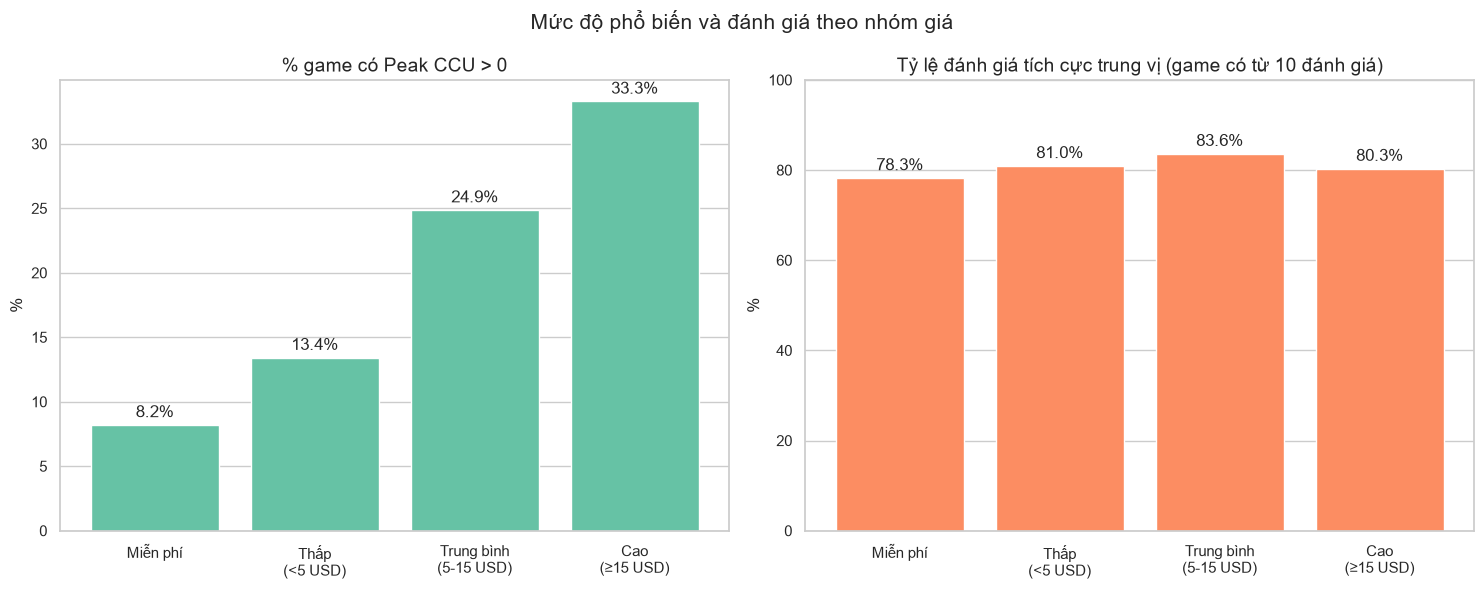

In [14]:
bang_gia = rq.groupby("Nhóm giá").agg(
    so_game=("Price", "size"),
    pct_co_nguoi_choi=("Peak CCU", lambda s: (s > 0).mean() * 100),
    ccu_trung_binh=("Peak CCU", "mean"),
    pct_tu_20k=("Owners_mid", lambda s: (s >= 35000).mean() * 100),
).reindex(thu_tu_gia)
bang_gia["ty_le_tich_cuc_trung_vi"] = rq_review.groupby("Nhóm giá")["Positive ratio"].median().reindex(thu_tu_gia)
display(bang_gia.round(1))

print("Tương quan Spearman giữa giá và tỷ lệ tích cực:",
      round(rq_review["Price"].corr(rq_review["Positive ratio"], method="spearman"), 2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(thu_tu_gia, bang_gia["pct_co_nguoi_choi"], edgecolor="white")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].set(title="% game có Peak CCU > 0", ylabel="%")

axes[1].bar(thu_tu_gia, bang_gia["ty_le_tich_cuc_trung_vi"], color=sns.color_palette()[1], edgecolor="white")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set_ylim(0, 100)
axes[1].set(title="Tỷ lệ đánh giá tích cực trung vị (game có từ 10 đánh giá)", ylabel="%")

for ax in axes:
    ax.set_xticks(range(len(thu_tu_gia)))
    ax.set_xticklabels([t.replace(" (", "\n(") for t in thu_tu_gia])
    ax.grid(axis="x", visible=False)

fig.suptitle("Mức độ phổ biến và đánh giá theo nhóm giá", fontsize=15)
plt.tight_layout()
plt.show()

Câu hỏi phụ: *Game miễn phí có lượng người chơi đồng thời cao hơn game trả phí không?*

In [15]:
mien_phi = rq[rq["Price"] == 0].sort_values("Peak CCU", ascending=False)
tra_phi = rq[rq["Price"] > 0]

print("Peak CCU trung bình - miễn phí:", round(mien_phi["Peak CCU"].mean(), 1), "| trả phí:", round(tra_phi["Peak CCU"].mean(), 1))
print("Peak CCU trung vị   - miễn phí:", mien_phi["Peak CCU"].median(), "| trả phí:", tra_phi["Peak CCU"].median())
print("% game có Peak CCU > 0 - miễn phí:", round((mien_phi["Peak CCU"] > 0).mean() * 100, 1),
      "| trả phí:", round((tra_phi["Peak CCU"] > 0).mean() * 100, 1))

print("\n3 game miễn phí có Peak CCU cao nhất:")
display(mien_phi[["Name", "Peak CCU"]].head(3))

ty_trong_top3 = mien_phi["Peak CCU"].head(3).sum() / mien_phi["Peak CCU"].sum() * 100
print("3 game này chiếm", round(ty_trong_top3, 1), "% tổng Peak CCU của tất cả game miễn phí")
print("Peak CCU trung bình game miễn phí khi bỏ 10 game lớn nhất:", round(mien_phi["Peak CCU"].iloc[10:].mean(), 1))

Peak CCU trung bình - miễn phí: 124.4 | trả phí: 34.0
Peak CCU trung vị   - miễn phí: 0.0 | trả phí: 0.0
% game có Peak CCU > 0 - miễn phí: 8.2 | trả phí: 17.6

3 game miễn phí có Peak CCU cao nhất:


,Name,Peak CCU
27,Counter-Strike 2,1013936
23,Dota 2,623941
13025,PUBG: BATTLEGROUNDS,314682


3 game này chiếm 58.9 % tổng Peak CCU của tất cả game miễn phí
Peak CCU trung bình game miễn phí khi bỏ 10 game lớn nhất: 26.9


Nhận xét:

- Giá càng cao thì tỷ lệ game phổ biến càng cao: tỷ lệ game có người chơi đồng thời là 8,2% (miễn phí), 13,4% (thấp), 24,9% (trung bình) và 33,3% (cao). Tỷ lệ game từ 20.000 người sở hữu cũng tăng từ 14,6% lên 24,5%.
- Tỷ lệ tích cực **cao nhất ở nhóm giá trung bình** (83,6%), thấp nhất ở nhóm miễn phí (78,3%). Chênh lệch giữa các nhóm chỉ khoảng 5 điểm, và tương quan giữa giá với tỷ lệ tích cực rất yếu (Spearman 0,12).
- **Game miễn phí:** Peak CCU *trung bình* của game miễn phí (124,4) cao hơn game trả phí (34,0), nhưng đó là do vài game rất lớn. Counter-Strike 2, Dota 2 và PUBG chiếm 58,9% tổng Peak CCU của game miễn phí. Bỏ 10 game lớn nhất thì trung bình chỉ còn 26,9, thấp hơn game trả phí. Chỉ 8,2% game miễn phí có người chơi đồng thời, so với 17,6% ở game trả phí.

**Trả lời câu hỏi phụ:** một game miễn phí *điển hình* **không** có nhiều người chơi đồng thời hơn game trả phí. Chỉ một số ít game miễn phí rất lớn kéo trung bình lên.

#### 2.4.8. RQ5 – Giá và đánh giá trong từng thể loại

Để tránh kết luận sai do khác biệt giữa các thể loại, ta xem lại mối liên hệ giữa giá với độ phổ biến và đánh giá **trong từng thể loại** (6 thể loại nhiều game nhất).

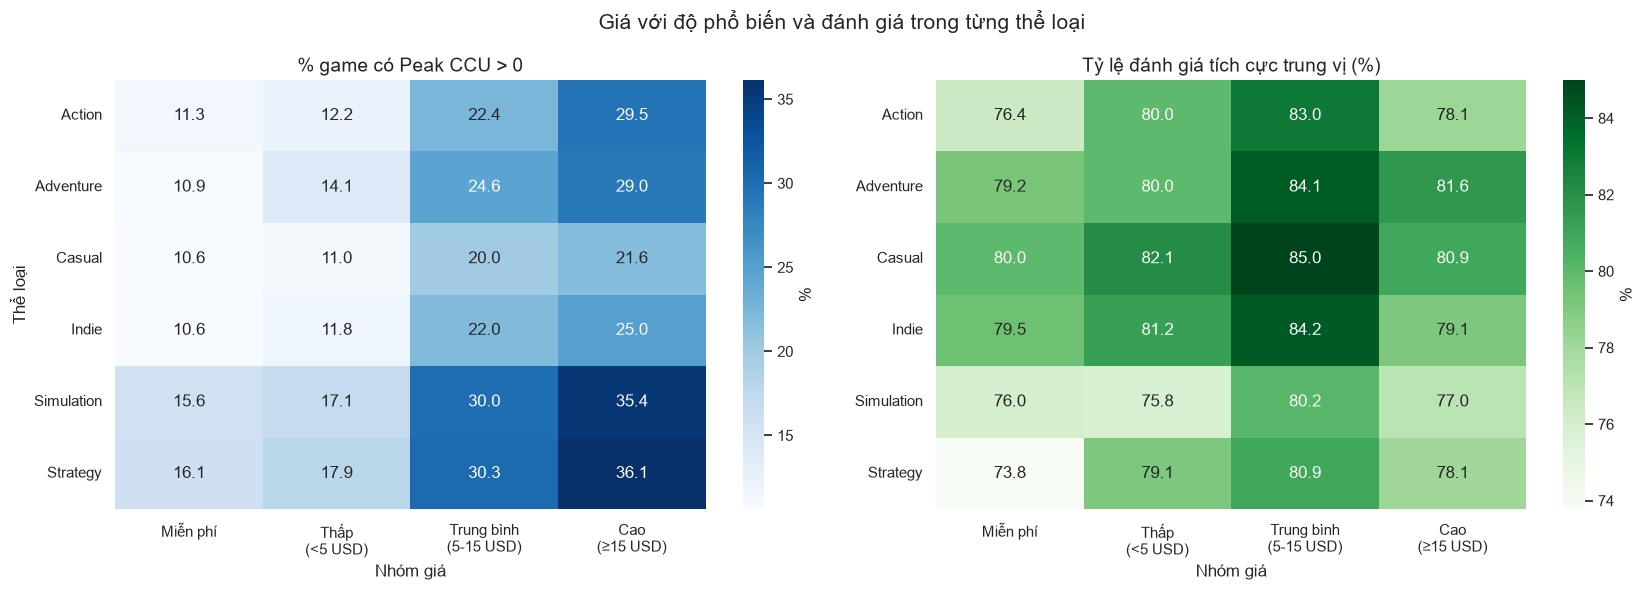

In [16]:
top6 = the_loai["Genre"].value_counts().head(6).index
d6 = the_loai[the_loai["Genre"].isin(top6)]

bang_ccu = d6.pivot_table(index="Genre", columns="Nhóm giá", values="Peak CCU",
                          aggfunc=lambda s: (s > 0).mean() * 100).reindex(columns=thu_tu_gia)
bang_tc = d6[d6["Total reviews"] >= 10].pivot_table(index="Genre", columns="Nhóm giá", values="Positive ratio",
                                                    aggfunc="median").reindex(columns=thu_tu_gia)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.heatmap(bang_ccu, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar_kws={"label": "%"})
axes[0].set(title="% game có Peak CCU > 0", xlabel="Nhóm giá", ylabel="Thể loại")

sns.heatmap(bang_tc, annot=True, fmt=".1f", cmap="Greens", ax=axes[1], cbar_kws={"label": "%"})
axes[1].set(title="Tỷ lệ đánh giá tích cực trung vị (%)", xlabel="Nhóm giá", ylabel="")

for ax in axes:
    ax.set_xticklabels([t.replace(" (", "\n(") for t in thu_tu_gia], rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.suptitle("Giá với độ phổ biến và đánh giá trong từng thể loại", fontsize=15)
plt.tight_layout()
plt.show()

Nhận xét:

- Trong **cả 6 thể loại**, tỷ lệ game có người chơi đồng thời đều tăng theo nhóm giá. Ví dụ Strategy tăng từ 16,1% (miễn phí) lên 36,1% (cao), Action từ 11,3% lên 29,5%.
- Trong cả 6 thể loại, tỷ lệ tích cực đều **cao nhất ở nhóm giá trung bình** (80,2–85,0%).
- Như vậy các xu hướng ở mục 2.4.7 không phải do khác biệt giữa các thể loại, mà xuất hiện trong từng thể loại.

**Trả lời RQ5:** giá có liên hệ cùng chiều với mức độ phổ biến: game có giá cao hơn thì tỷ lệ có người chơi và có nhiều người sở hữu cao hơn. Giá liên hệ rất yếu với đánh giá: nhóm giá trung bình được đánh giá tốt nhất, nhưng chênh lệch chỉ vài điểm phần trăm.

### 2.5. Tổng kết trả lời câu hỏi nghiên cứu

**RQ1 – Yếu tố liên quan đến mức độ phổ biến**
- Số người sở hữu liên hệ cùng chiều với Peak CCU ở mức trung bình (Spearman 0,45) và liên hệ mạnh với tổng số đánh giá (0,73).
- Thể loại có liên hệ với độ phổ biến: Massively Multiplayer, RPG và Strategy có tỷ lệ game phổ biến cao nhất. Casual và Indie có nhiều game nhất nhưng tỷ lệ phổ biến thấp nhất.
- Giá cao hơn đi kèm tỷ lệ game phổ biến cao hơn (xem RQ5).

**RQ2 – Yếu tố liên quan đến đánh giá tích cực**
- Phần lớn game được đánh giá tốt (trung vị 81,2% tích cực).
- Đánh giá của người chơi và giới phê bình tương đồng ở mức khá (Spearman 0,58).
- Massively Multiplayer có đánh giá thấp hơn hẳn các thể loại khác (66,7%).
- Các tính năng hoàn thiện game (Achievements, Steam Cloud, hỗ trợ tay cầm) đi kèm đánh giá cao hơn khoảng 6–7 điểm. Tính năng chơi trực tuyến nhiều người đi kèm đánh giá thấp hơn.

**RQ5 – Giá bán với độ phổ biến và đánh giá**
- Giá càng cao thì tỷ lệ game phổ biến càng cao (8,2% ở nhóm miễn phí và 33,3% ở nhóm giá cao), xu hướng này đúng trong cả 6 thể loại lớn.
- Game miễn phí điển hình không có nhiều người chơi hơn game trả phí, chỉ vài game rất lớn kéo trung bình lên.
- Giá liên hệ rất yếu với đánh giá (Spearman 0,12). Nhóm giá trung bình (5–15 USD) được đánh giá tốt nhất.

**Hạn chế**
- Đây là **mối liên hệ**, không phải quan hệ nhân quả. Ví dụ game giá cao thường do công ty lớn làm, có ngân sách quảng cáo, nên phổ biến hơn không hẳn vì giá.
- Giá trong dữ liệu là giá hiện tại, không nhất thiết là giá lúc người chơi mua game.
- Estimated owners chỉ là khoảng ước tính, và 84% game có Peak CCU = 0, nên các tương quan bị giới hạn.
- `User score` gần như rỗng và Metacritic chỉ có ở khoảng 4.000 game, nên phần so sánh với giới phê bình chỉ dựa trên nhóm game lớn.